In [2]:
import os
import torch
import time
import numpy as np
import tifffile
from PIL import Image
from tqdm import tqdm
DATA_DIR       = "../data"
CHECKPOINT_DIR = "../checkpoints"

IMAGE_PATH      = os.path.join(DATA_DIR, "mitochondria_train_01.tif")
MASK_PATH       = os.path.join(DATA_DIR, "mitochondria_train_masks_01.tif")
BEST_MODEL_PATH = os.path.join(CHECKPOINT_DIR, "best_model.pth")
HISTORY_PATH    = os.path.join(CHECKPOINT_DIR, "training_history.json")
CONFIG_PATH     = os.path.join(CHECKPOINT_DIR, "config.json")
SUMMARY_PATH    = os.path.join(CHECKPOINT_DIR, "summary.json")

SEED       = 42
VAL_RATIO  = 0.2
PATCH_SIZE = 256
BATCH_SIZE = 2

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.set_num_threads(os.cpu_count())

for path in [IMAGE_PATH, MASK_PATH, BEST_MODEL_PATH, HISTORY_PATH, CONFIG_PATH, SUMMARY_PATH]:
    status = "OK      " if os.path.exists(path) else "MANQUANT"
    print(f"{status}: {path}")

print("Device      :", device)
print("Threads CPU :", torch.get_num_threads())

OK      : ../data\mitochondria_train_01.tif
OK      : ../data\mitochondria_train_masks_01.tif
OK      : ../checkpoints\best_model.pth
OK      : ../checkpoints\training_history.json
OK      : ../checkpoints\config.json
MANQUANT: ../checkpoints\summary.json
Device      : cpu
Threads CPU : 8


In [3]:
import torch
import numpy as np
from transformers import SamModel, SamProcessor

processor = SamProcessor.from_pretrained("facebook/sam-vit-base")

model = SamModel.from_pretrained("facebook/sam-vit-base")
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.to(device)
model.eval()

def get_bounding_box_simple(mask):
    ys, xs = np.where(mask > 0)
    return [int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())]

print("Modèle chargé sur :", device)
print("Nombre de paramètres :", sum(p.numel() for p in model.parameters()) / 1e6, "M")

Loading weights: 100%|██████████| 314/314 [00:00<00:00, 552.99it/s]


Modèle chargé sur : cpu
Nombre de paramètres : 93.735728 M


In [4]:
from datasets import Dataset
def patchify_array(image, patch_size):
    h, w = image.shape
    ph, pw = patch_size
    n_h = h // ph
    n_w = w // pw
    patches = image[:n_h * ph, :n_w * pw].reshape(n_h, ph, n_w, pw)
    patches = patches.swapaxes(1, 2)
    return patches

large_images = tifffile.imread(IMAGE_PATH)
large_masks  = tifffile.imread(MASK_PATH)

all_img_patches = []
for img in range(large_images.shape[0]):
    patches = patchify_array(large_images[img], (PATCH_SIZE, PATCH_SIZE))
    for i in range(patches.shape[0]):
        for j in range(patches.shape[1]):
            all_img_patches.append(patches[i, j, :, :])
images = np.array(all_img_patches)

all_mask_patches = []
for img in range(large_masks.shape[0]):
    patches = patchify_array(large_masks[img], (PATCH_SIZE, PATCH_SIZE))
    for i in range(patches.shape[0]):
        for j in range(patches.shape[1]):
            m = (patches[i, j, :, :] / 255.).astype(np.uint8)
            all_mask_patches.append(m)
masks = np.array(all_mask_patches)

valid_indices = [i for i, mask in enumerate(masks) if mask.max() != 0]
filtered_images = images[valid_indices]
filtered_masks  = masks[valid_indices]

dataset_dict = {
    "image": [Image.fromarray(img) for img in filtered_images],
    "label": [Image.fromarray(mask) for mask in filtered_masks],
}
dataset = Dataset.from_dict(dataset_dict)

torch.manual_seed(SEED)
np.random.seed(SEED)
split = dataset.train_test_split(test_size=VAL_RATIO, seed=SEED)
train_hf = split["train"]
val_hf   = split["test"]

print("Patchs totaux filtrés :", len(dataset))
print("Patchs d'entraînement :", len(train_hf))
print("Patchs de validation  :", len(val_hf))

Patchs totaux filtrés : 1642
Patchs d'entraînement : 1313
Patchs de validation  : 329


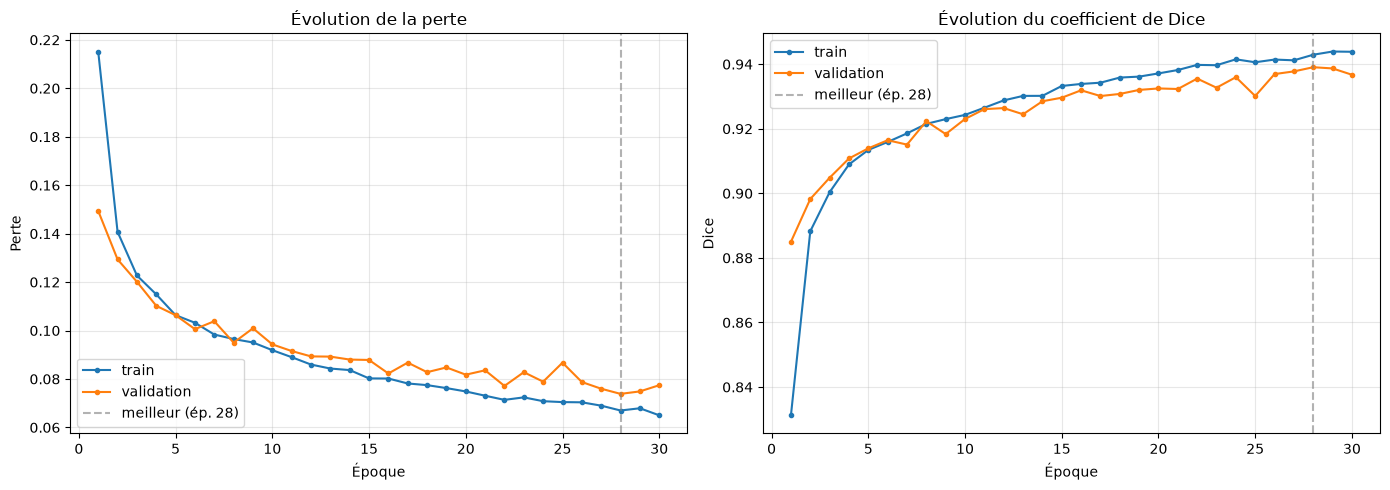

Meilleure époque  : 28
Meilleur val_dice : 0.9391


In [5]:
import json
import matplotlib.pyplot as plt

with open(HISTORY_PATH, "r") as f:
    history = json.load(f)

epochs = np.arange(1, len(history["train_loss"]) + 1)
best_epoch = int(np.argmax(history["val_dice"])) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs, history["train_loss"], label="train", marker="o", markersize=3)
axes[0].plot(epochs, history["val_loss"], label="validation", marker="o", markersize=3)
axes[0].axvline(best_epoch, color="gray", linestyle="--", alpha=0.6, label=f"meilleur (ép. {best_epoch})")
axes[0].set_xlabel("Époque")
axes[0].set_ylabel("Perte")
axes[0].set_title("Évolution de la perte")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, history["train_dice"], label="train", marker="o", markersize=3)
axes[1].plot(epochs, history["val_dice"], label="validation", marker="o", markersize=3)
axes[1].axvline(best_epoch, color="gray", linestyle="--", alpha=0.6, label=f"meilleur (ép. {best_epoch})")
axes[1].set_xlabel("Époque")
axes[1].set_ylabel("Dice")
axes[1].set_title("Évolution du coefficient de Dice")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, "training_curves.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"Meilleure époque  : {best_epoch}")
print(f"Meilleur val_dice : {history['val_dice'][best_epoch-1]:.4f}")

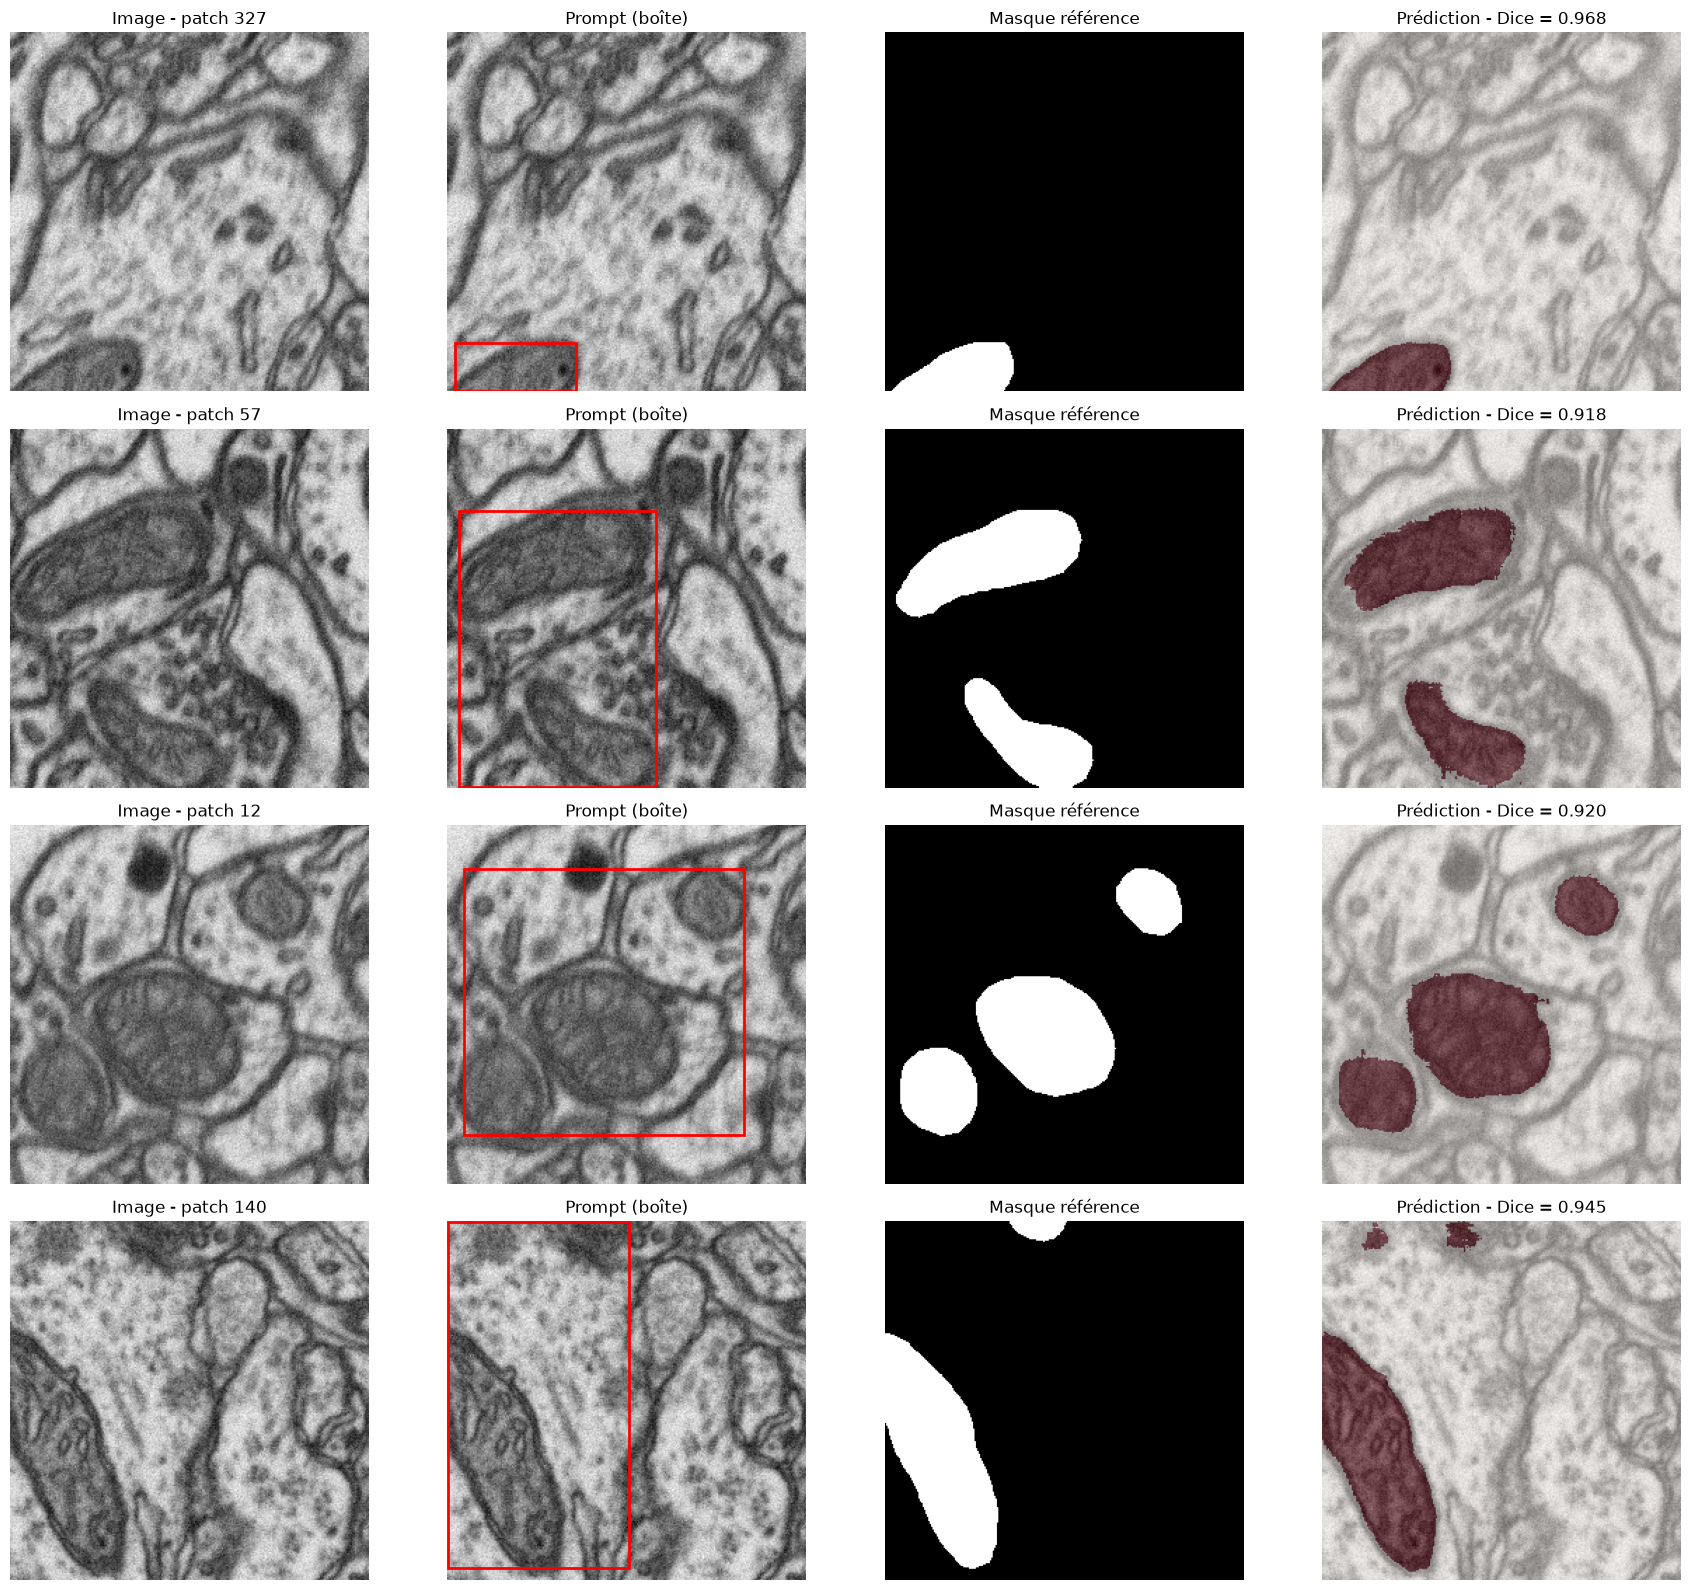

In [6]:
import random
from matplotlib.patches import Rectangle

random.seed(42)
n_examples = 4
indices = random.sample(range(len(val_hf)), n_examples)

fig, axes = plt.subplots(n_examples, 4, figsize=(18, 4 * n_examples))

for row, idx in enumerate(indices):
    item = val_hf[idx]
    image_pil = item["image"]
    image_np = np.array(image_pil)
    gt_mask = np.array(item["label"])

    bbox = get_bounding_box_simple(gt_mask)
    x_min, y_min, x_max, y_max = bbox

    inputs = processor(image_pil, input_boxes=[[bbox]], return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs, multimask_output=False)

    masks = processor.image_processor.post_process_masks(
        outputs.pred_masks.cpu(),
        inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu()
    )[0]

    pred_prob = torch.sigmoid(masks).squeeze().numpy()
    pred_mask = (pred_prob > 0.5).astype(np.uint8)

    inter = np.logical_and(pred_mask, gt_mask).sum()
    union = pred_mask.sum() + gt_mask.sum()
    dice = 2.0 * inter / (union + 1e-6)

    axes[row, 0].imshow(image_np, cmap="gray")
    axes[row, 0].set_title(f"Image - patch {idx}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(image_np, cmap="gray")
    axes[row, 1].add_patch(Rectangle(
        (x_min, y_min), x_max - x_min, y_max - y_min,
        edgecolor="red", facecolor="none", linewidth=2
    ))
    axes[row, 1].set_title("Prompt (boîte)")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(gt_mask, cmap="gray")
    axes[row, 2].set_title("Masque référence")
    axes[row, 2].axis("off")

    axes[row, 3].imshow(image_np, cmap="gray")
    axes[row, 3].imshow(pred_mask, cmap="Reds", alpha=0.4)
    axes[row, 3].set_title(f"Prédiction - Dice = {dice:.3f}")
    axes[row, 3].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, "validation_patches_predictions.png"), dpi=150, bbox_inches="tight")
plt.show()

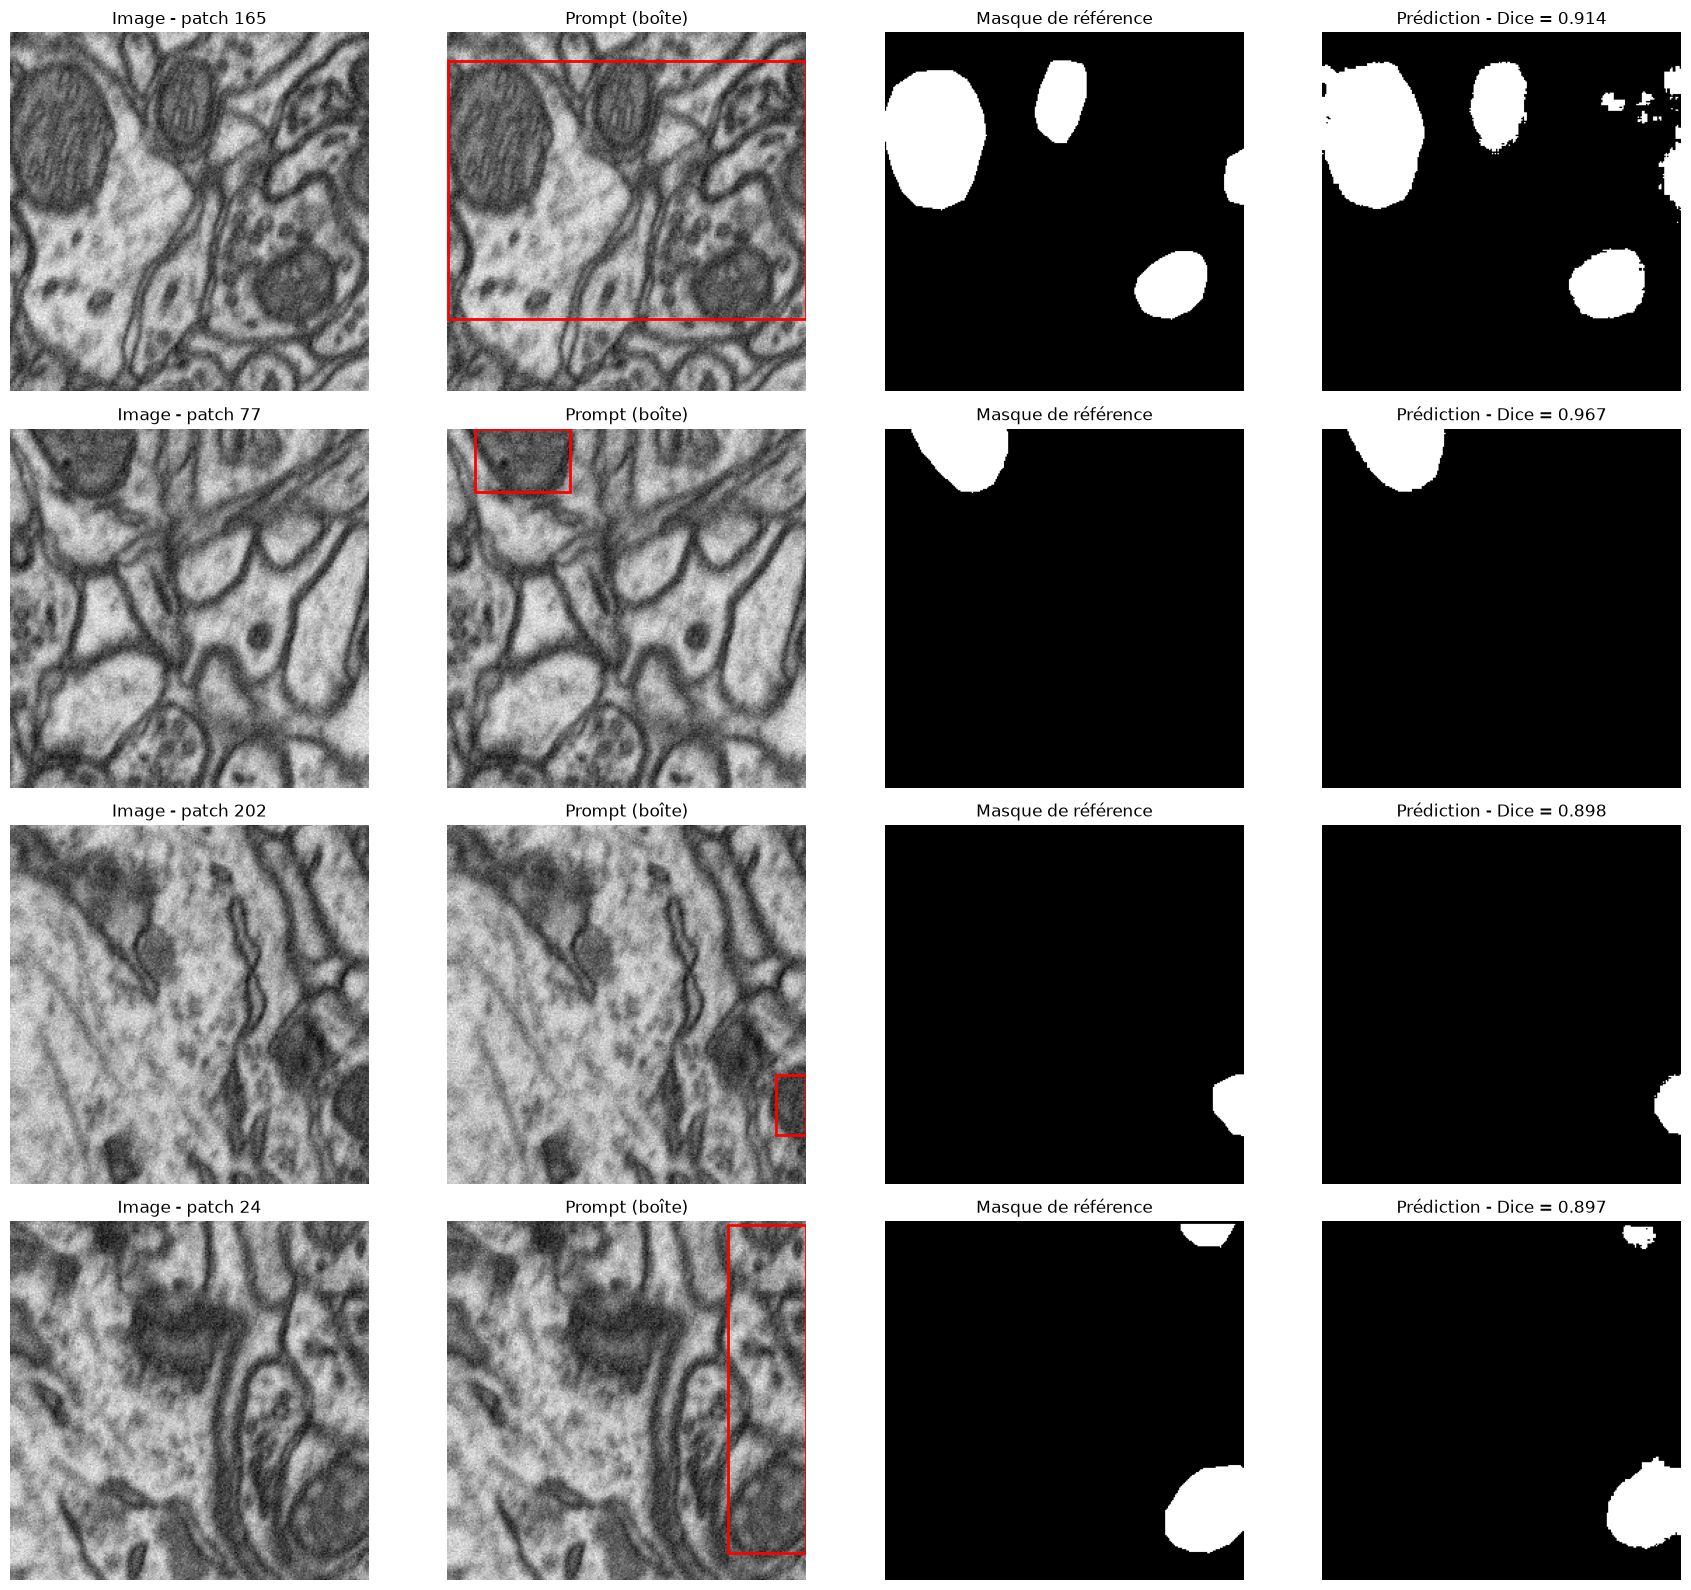

In [7]:
random.seed(7)
n_examples = 4
indices = random.sample(range(len(val_hf)), n_examples)

fig, axes = plt.subplots(n_examples, 4, figsize=(18, 4 * n_examples))

for row, idx in enumerate(indices):
    item = val_hf[idx]
    image_pil = item["image"]
    image_np = np.array(image_pil)
    gt_mask = np.array(item["label"])

    bbox = get_bounding_box_simple(gt_mask)
    x_min, y_min, x_max, y_max = bbox

    inputs = processor(image_pil, input_boxes=[[bbox]], return_tensors="pt")
    inputs = {k: v.to(device) for k, v in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs, multimask_output=False)

    masks = processor.image_processor.post_process_masks(
        outputs.pred_masks.cpu(),
        inputs["original_sizes"].cpu(),
        inputs["reshaped_input_sizes"].cpu()
    )[0]

    pred_prob = torch.sigmoid(masks).squeeze().numpy()
    pred_mask = (pred_prob > 0.5).astype(np.uint8)

    inter = np.logical_and(pred_mask, gt_mask).sum()
    union = pred_mask.sum() + gt_mask.sum()
    dice = 2.0 * inter / (union + 1e-6)

    axes[row, 0].imshow(image_np, cmap="gray")
    axes[row, 0].set_title(f"Image - patch {idx}")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(image_np, cmap="gray")
    axes[row, 1].add_patch(Rectangle(
        (x_min, y_min), x_max - x_min, y_max - y_min,
        edgecolor="red", facecolor="none", linewidth=2
    ))
    axes[row, 1].set_title("Prompt (boîte)")
    axes[row, 1].axis("off")

    axes[row, 2].imshow(gt_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 2].set_title("Masque de référence")
    axes[row, 2].axis("off")

    axes[row, 3].imshow(pred_mask, cmap="gray", vmin=0, vmax=1)
    axes[row, 3].set_title(f"Prédiction - Dice = {dice:.3f}")
    axes[row, 3].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(CHECKPOINT_DIR, "validation_patches_bw.png"), dpi=150, bbox_inches="tight")
plt.show()